# 02D: Annotate celltypes manually


In [1]:
import spatialdata as sd
import spatialdata_plot
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import scanpy as sc
import scanpy.external as sce
import matplotlib.pyplot as plt
import anndata as ad
import numpy as np
import sys


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/importlib/__init__.py:126: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  return _bootstrap._gcd_import(name[level:], package, level)


In [2]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")

## prepare the data

In [10]:
sdata_sample1 = sd.read_zarr(data_dir / "xenium_sample1.zarr")
sdata_sample2 = sd.read_zarr(data_dir / "xenium_sample2.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


In [11]:
sdata_sample1["table"].obs["sample"] = "sample1"
sdata_sample2["table"].obs["sample"] = "sample2"

## preproc

In [12]:
adata_gexp_raw = ad.concat([sdata_sample1["table"], sdata_sample2["table"]])

adata_gexp_raw.obs_names_make_unique()

adata_gexp_raw.var["mt"] = adata_gexp_raw.var_names.str.startswith("MT-")
adata_gexp_raw.var["ribo"] = adata_gexp_raw.var_names.str.startswith(("RPS", "RPL"))
adata_gexp_raw.var["hb"] = adata_gexp_raw.var_names.str.contains("^HB[^(P)]")

sc.pp.calculate_qc_metrics(
    adata_gexp_raw,
    qc_vars=["mt", "ribo", "hb"],
    percent_top=[],  # needed because of small panel
    inplace=True,
    log1p=True,
)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


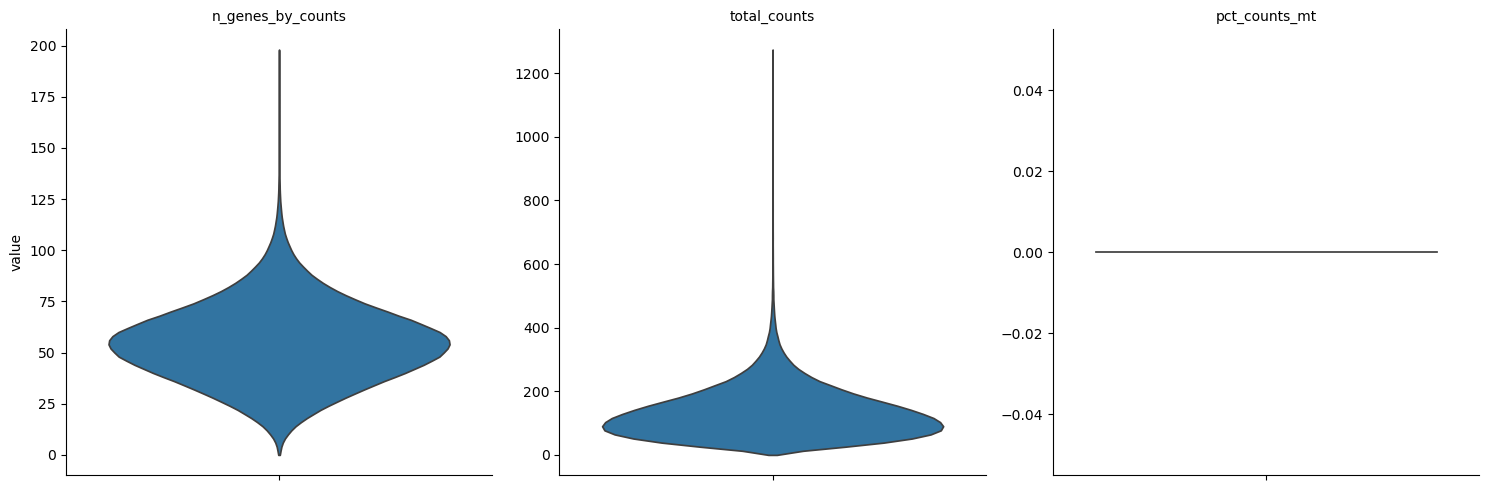

In [13]:
sc.pl.violin(
    adata_gexp_raw,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.2,
    multi_panel=True,
    stripplot=False, # too many points to see anything
)

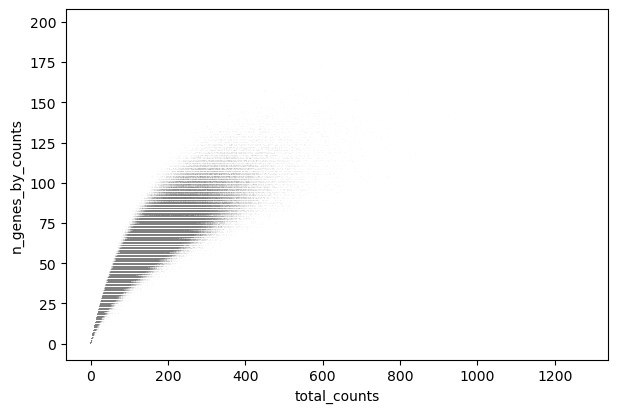

In [14]:
sc.pl.scatter(adata_gexp_raw, "total_counts", "n_genes_by_counts")

In [24]:
print(adata_gexp_raw.shape)

# not doing this step because our resulting data is then out of sync when we merge with morphology
# sc.pp.filter_cells(adata_gexp_raw, min_genes=100) # only cells with at least 100 genes expressed

sc.pp.filter_genes(adata_gexp_raw, min_cells=100) # only genes expressed in at least 100 cells
print(adata_gexp_raw.shape)

(940131, 380)
(940131, 380)


In [15]:
adata_gexp_raw.layers["counts"] = adata_gexp_raw.X.copy()
sc.pp.normalize_total(adata_gexp_raw)
sc.pp.log1p(adata_gexp_raw)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:234: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))


In [20]:
# drops to 100 genes, we don't want that - let's trust the panel

sc.pp.highly_variable_genes(adata_gexp_raw, flavor="seurat", batch_key="sample")
adata_gexp_hvg = adata_gexp_raw[:, adata_gexp_raw.var["highly_variable"]].copy()
adata_gexp_hvg

# adata_gexp_hvg = adata_gexp_raw.copy()

AnnData object with n_obs × n_vars = 940131 × 101
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg'
    obsm: 'spatial'
    layers: 'counts'

In [10]:
adata_gexp_hvg.obs["sample"]

0           sample1
1           sample1
2           sample1
3           sample1
4           sample1
             ...   
365599-1    sample2
365600-1    sample2
365601-1    sample2
365602-1    sample2
365603-1    sample2
Name: sample, Length: 940131, dtype: category
Categories (2, object): ['sample1', 'sample2']

In [11]:
adata_gexp_hvg

AnnData object with n_obs × n_vars = 940131 × 380
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'log1p'
    obsm: 'spatial'
    layers: 'counts'

In [12]:
sc.tl.pca(adata_gexp_hvg)
sce.pp.harmony_integrate(adata_gexp_hvg, key="sample", max_iter_harmony=10)

2025-05-18 13:18:21,646 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-05-18 13:19:28,527 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-05-18 13:19:32,511 - harmonypy - INFO - Iteration 1 of 10
2025-05-18 13:27:39,319 - harmonypy - INFO - Iteration 2 of 10
2025-05-18 13:35:39,283 - harmonypy - INFO - Converged after 2 iterations


In [13]:
%%time

sc.pp.neighbors(adata_gexp_hvg, use_rep="X_pca_harmony")

CPU times: user 4min 29s, sys: 5.05 s, total: 4min 34s
Wall time: 4min 39s


In [14]:
%%time

sc.tl.umap(adata_gexp_hvg)

CPU times: user 1h 44min 21s, sys: 4.72 s, total: 1h 44min 26s
Wall time: 22min 29s


In [15]:
%%time

sc.tl.leiden(adata_gexp_hvg)

<timed eval>:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.


CPU times: user 34min 52s, sys: 47.9 s, total: 35min 40s
Wall time: 35min 45s


In [17]:
adata_gexp_hvg.write(data_dir / "xenium_gexp_harmony.h5ad")

In [29]:
adata_gexp_hvg = ad.read_h5ad(data_dir / "xenium_gexp_harmony.h5ad")
adata_gexp_hvg

AnnData object with n_obs × n_vars = 940131 × 380
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

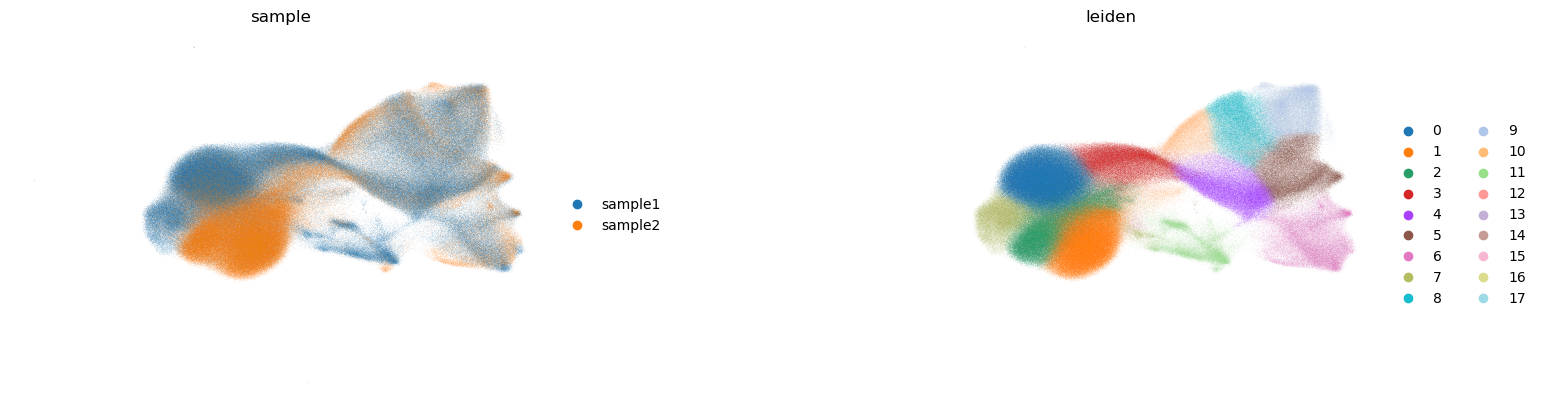

In [6]:
sc.pl.umap(
    adata_gexp_hvg,
    color=["sample", "leiden"],
    wspace=0.4,
    title=["sample", "leiden"],
    frameon=False,
)

## Manually annotate

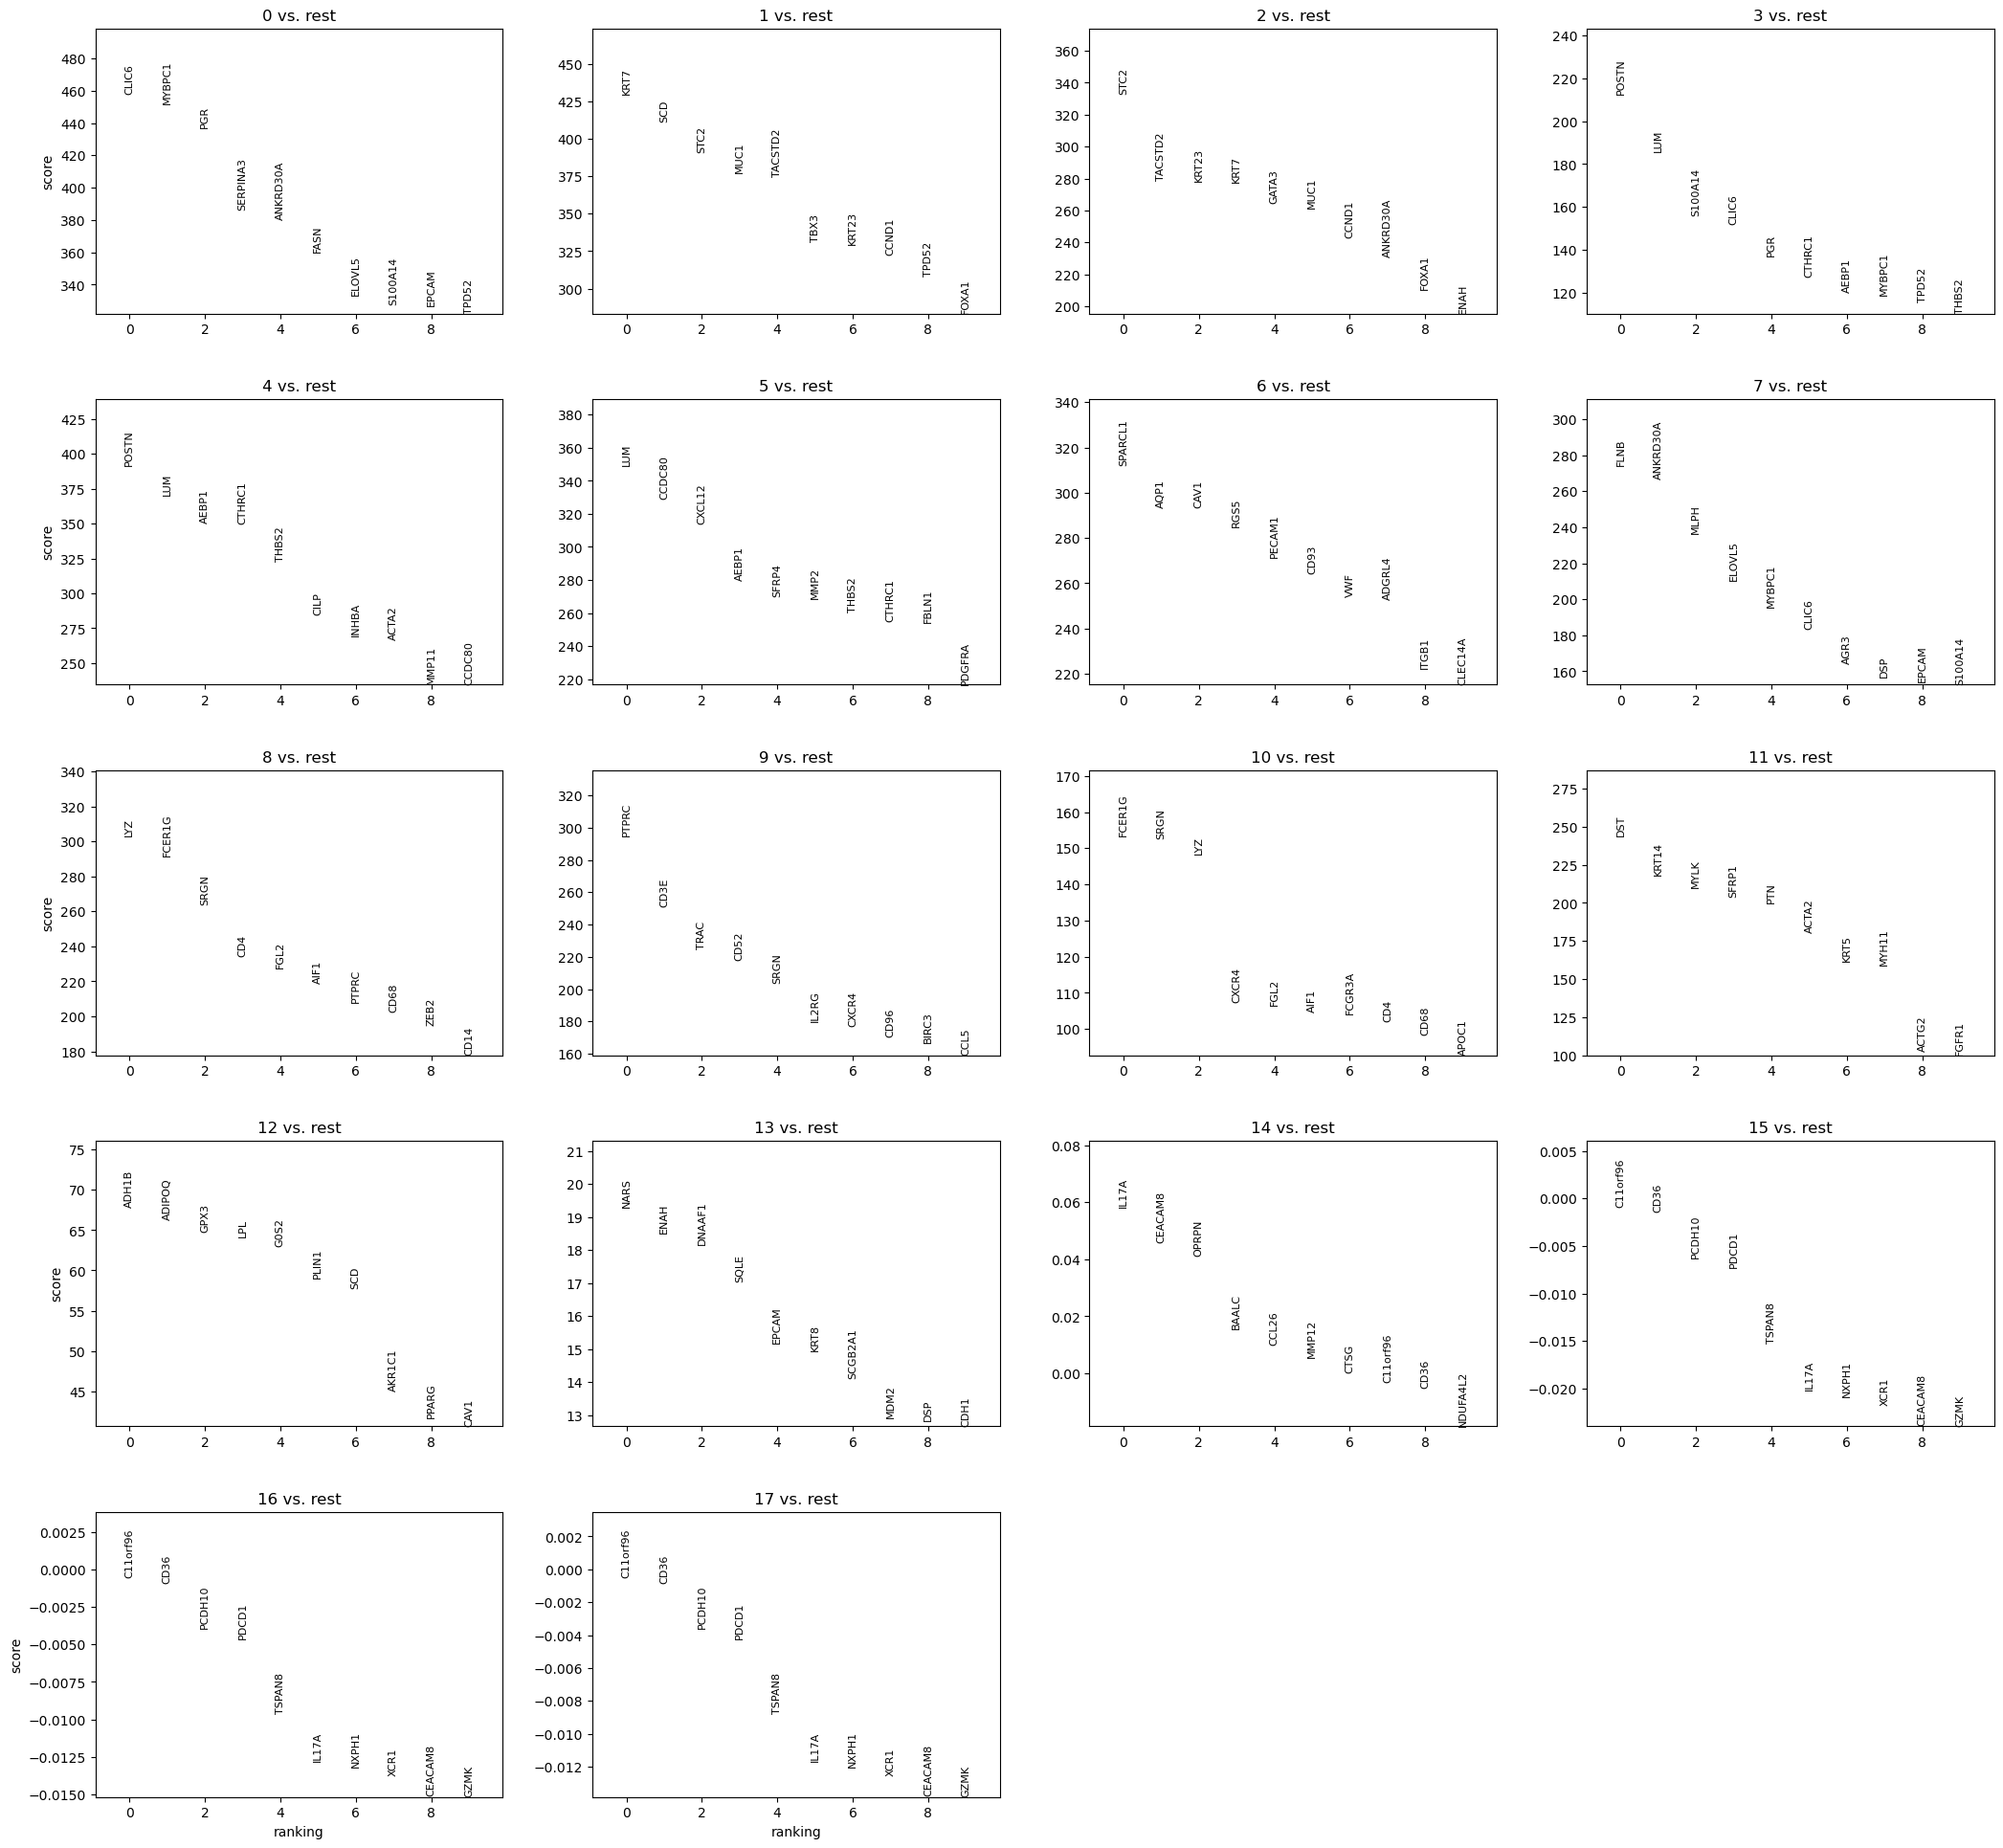

In [7]:
sc.tl.rank_genes_groups(
    adata_gexp_hvg,
    groupby="leiden",
    method="wilcoxon",               # or "t-test", "logreg"
    corr_method="benjamini-hochberg",# FDR correction
    n_genes=adata_gexp_hvg.shape[1]           # test all genes
)

# 3. Quick visualization of the top markers
sc.pl.rank_genes_groups(
    adata_gexp_hvg,
    n_genes=10,
    sharey=False
)

In [9]:

# 4. Extract the top N marker genes per cluster into a DataFrame
#    Here we take the top 5 per cluster
top_n = 10
ranks = adata_gexp_hvg.uns["rank_genes_groups"]
clusters = ranks["names"].dtype.names

top_markers = pd.DataFrame(
    {cluster: ranks["names"][cluster][:top_n] for cluster in clusters},
    index=[f"rank_{i+1}" for i in range(top_n)]
)

for col in top_markers.columns:
    print(col, ", ".join(top_markers[col].values))

0 CLIC6, MYBPC1, PGR, SERPINA3, ANKRD30A, FASN, ELOVL5, S100A14, EPCAM, TPD52
1 KRT7, SCD, STC2, MUC1, TACSTD2, TBX3, KRT23, CCND1, TPD52, FOXA1
2 STC2, TACSTD2, KRT23, KRT7, GATA3, MUC1, CCND1, ANKRD30A, FOXA1, ENAH
3 POSTN, LUM, S100A14, CLIC6, PGR, CTHRC1, AEBP1, MYBPC1, TPD52, THBS2
4 POSTN, LUM, AEBP1, CTHRC1, THBS2, CILP, INHBA, ACTA2, MMP11, CCDC80
5 LUM, CCDC80, CXCL12, AEBP1, SFRP4, MMP2, THBS2, CTHRC1, FBLN1, PDGFRA
6 SPARCL1, AQP1, CAV1, RGS5, PECAM1, CD93, VWF, ADGRL4, ITGB1, CLEC14A
7 FLNB, ANKRD30A, MLPH, ELOVL5, MYBPC1, CLIC6, AGR3, DSP, EPCAM, S100A14
8 LYZ, FCER1G, SRGN, CD4, FGL2, AIF1, PTPRC, CD68, ZEB2, CD14
9 PTPRC, CD3E, TRAC, CD52, SRGN, IL2RG, CXCR4, CD96, BIRC3, CCL5
10 FCER1G, SRGN, LYZ, CXCR4, FGL2, AIF1, FCGR3A, CD4, CD68, APOC1
11 DST, KRT14, MYLK, SFRP1, PTN, ACTA2, KRT5, MYH11, ACTG2, FGFR1
12 ADH1B, ADIPOQ, GPX3, LPL, G0S2, PLIN1, SCD, AKR1C1, PPARG, CAV1
13 NARS, ENAH, DNAAF1, SQLE, EPCAM, KRT8, SCGB2A1, MDM2, DSP, CDH1
14 IL17A, CEACAM8, OPRPN, BAALC, 

In [17]:
!curl -O https://cf.10xgenomics.com/samples/xenium/1.0.2/Xenium_V1_FFPE_Human_Breast_Addon_Input/Xenium_V1_FFPE_Human_Breast_Addon_Input_gene_groups.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  5403  100  5403    0     0   5962      0 --:--:-- --:--:-- --:--:--  6036


In [19]:
gene_groups_10x = pd.read_csv("Xenium_V1_FFPE_Human_Breast_Addon_Input_gene_groups.csv")
gene_groups_10x

,gene,group
0,ABCC11,Breast cancer
1,ACTA2,Smooth muscle cells
2,ACTG2,Breast myoepithelial cells
3,ADAM9,Breast glandular cells
4,ADGRE5,Dendritic cells
...,...,...
275,VWF,Endothelial cells
276,WARS,Endothelial cells
277,ZEB1,NaN
278,ZEB2,NaN


In [31]:
marker_dict = (
    gene_groups_10x.dropna(subset=["group"])
      .groupby("group")["gene"]
      .apply(list)
      .to_dict()
)

In [32]:
for ct, genes in marker_dict.items():
    sc.tl.score_genes(
      adata_gexp_hvg,
      gene_list=genes,
      score_name=f"{ct}_score",
      use_raw=False
    )

In [33]:
score_cols = [f"{ct}_score" for ct in marker_dict]

max_scores = adata_gexp_hvg.obs[score_cols].max(axis=1)
best_ct   = adata_gexp_hvg.obs[score_cols].idxmax(axis=1).str.replace("_score", "")

# assign, with an optional threshold
threshold = 0.0
adata_gexp_hvg.obs["predicted_celltype"] = np.where(
    max_scores > threshold,
    best_ct,
    "Unknown"
)

adata_gexp_hvg.obs["predicted_celltype"] 

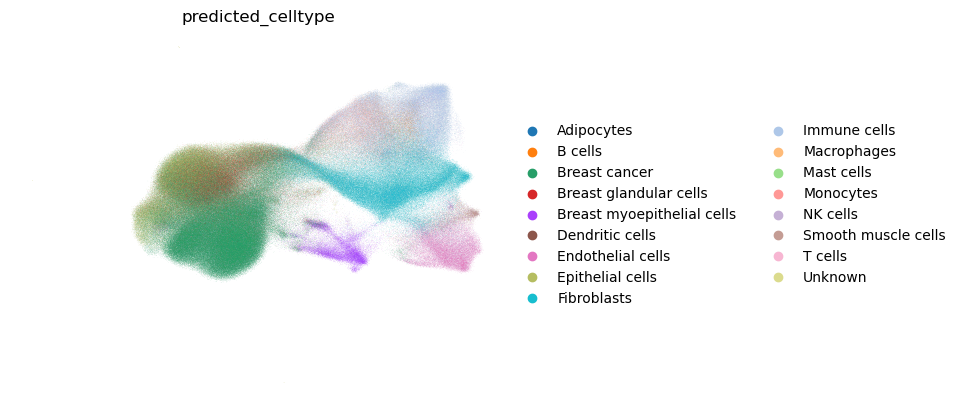

In [34]:
sc.pl.umap(
    adata_gexp_hvg,
    color=["predicted_celltype"],
    wspace=0.4,
    frameon=False,
)

In [36]:
adata_gexp_hvg.write(data_dir / "xenium_gexp_celltypes.h5ad")

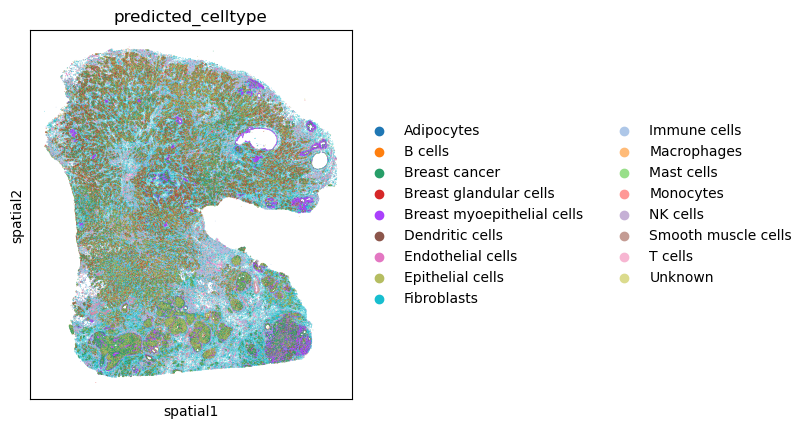

In [40]:
sc.pl.spatial(adata_gexp_hvg[adata_gexp_hvg.obs["sample"] == "sample1"], color="predicted_celltype", spot_size=20)

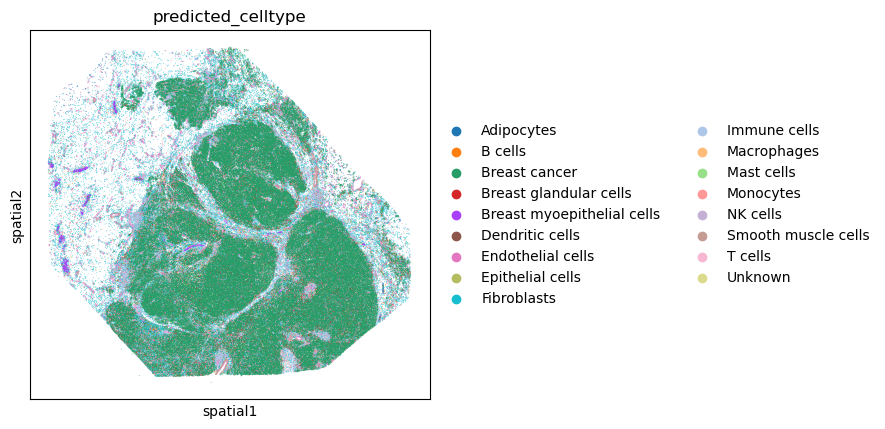

In [41]:
sc.pl.spatial(adata_gexp_hvg[adata_gexp_hvg.obs["sample"] == "sample2"], color="predicted_celltype", spot_size=20)